In [1]:
!pip install -q -U datasets huggingface_hub

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

np.random.seed(42)
tf.random.set_seed(42)

print("Libraries upgraded and imported successfully!")
print("TensorFlow version:", tf.__version__)

Libraries imported successfully!
TensorFlow version: 2.21.0


In [2]:
!pip -q install datasets

In [5]:
import pandas as pd

# Load the dataset from the local CSV file
local_csv_path = "/content/IMDB Dataset.csv"
full_df = pd.read_csv(local_csv_path)

# Map positive/negative sentiments to 1 and 0
full_df['label'] = full_df['sentiment'].map({'positive': 1, 'negative': 0})

# Select positive and negative reviews
positive_reviews = full_df[full_df["label"] == 1].sample(
    n=2500, random_state=42
)

negative_reviews = full_df[full_df["label"] == 0].sample(
    n=2500, random_state=42
)

# Combine the selected reviews
df = pd.concat(
    [positive_reviews, negative_reviews],
    ignore_index=True
).sample(frac=1, random_state=42).reset_index(drop=True)

print("Dataset shape:", df.shape)
print("\nSentiment distribution:")
print(df["label"].value_counts().sort_index())

# Display sample reviews
display(df.head())

Dataset shape: (5000, 3)

Sentiment distribution:
label
0    2500
1    2500
Name: count, dtype: int64


,review,sentiment,label
0,"Why would this film be so good, but only gross...",positive,1
1,"The name ""cult movie"" is often given to films ...",negative,0
2,Another stinker from the PM Entertainment grou...,negative,0
3,It really isn't hard to understand this movie!...,positive,1
4,"Make no mistake, Maureen O'Sullivan is easily ...",positive,1


In [9]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"<.*?>", " ", text)       # Remove HTML tags
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)    # Keep letters
    text = re.sub(r"\s+", " ", text).strip()
    return text

# Updated 'text' to 'review' to match your DataFrame's columns
df["clean_review"] = df["review"].apply(clean_text)

print("Original review:")
print(df["review"].iloc[0][:300])

print("\nCleaned review:")
print(df["clean_review"].iloc[0][:300])

Original review:
Why would this film be so good, but only gross an estimated $95,000,000 and have NO award nominations? John Travolta knows what he's doing. He knows he's Michael, a cigar smoking, womanizing, magical arch angel that came down to live with a dying lady and is now in a car with the staff of "The Natio

Cleaned review:
why would this film be so good but only gross an estimated and have no award nominations john travolta knows what he s doing he knows he s michael a cigar smoking womanizing magical arch angel that came down to live with a dying lady and is now in a car with the staff of the national mirror and thei


In [10]:
X = df["clean_review"].values
y = df["label"].values

# First, separate 15% for testing
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y,
    test_size=0.15,
    random_state=42,
    stratify=y
)

# Then separate 15% of the full dataset for validation
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val,
    test_size=0.15 / 0.85,
    random_state=42,
    stratify=y_train_val
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

Training samples: 3500
Validation samples: 750
Testing samples: 750


In [11]:
MAX_WORDS = 10000
MAX_LEN = 200

# Create tokenizer
tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)

# Learn vocabulary from training reviews only
tokenizer.fit_on_texts(X_train)

# Convert text into integer sequences
X_train_seq = tokenizer.texts_to_sequences(X_train)
X_val_seq = tokenizer.texts_to_sequences(X_val)
X_test_seq = tokenizer.texts_to_sequences(X_test)

# Pad sequences to equal length
X_train_pad = pad_sequences(
    X_train_seq, maxlen=MAX_LEN, padding="post", truncating="post"
)

X_val_pad = pad_sequences(
    X_val_seq, maxlen=MAX_LEN, padding="post", truncating="post"
)

X_test_pad = pad_sequences(
    X_test_seq, maxlen=MAX_LEN, padding="post", truncating="post"
)

print("Training data shape:", X_train_pad.shape)
print("Validation data shape:", X_val_pad.shape)
print("Testing data shape:", X_test_pad.shape)
print("\nSample encoded sequence:")
print(X_train_pad[0][:30])

Training data shape: (3500, 200)
Validation data shape: (750, 200)
Testing data shape: (750, 200)

Sample encoded sequence:
[  15 2191   15    8  199  431   10  163    1   60  794    5    2 9845
  410  209   42   88    2 1722 1141   15   70   15    2  370 1522 6353
  130   22]


In [19]:
# 1. Build the model structure
model = Sequential([
    Embedding(input_dim=MAX_WORDS, output_dim=128),
    LSTM(64, dropout=0.2, recurrent_dropout=0.2),
    Dense(32, activation="relu"),
    Dropout(0.5),
    Dense(1, activation="sigmoid")
])

# 2. Compile the model
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print(model.summary())

# 3. Define early stopping callback
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

# 4. Train the model
history = model.fit(
    X_train_pad,
    y_train,
    validation_data=(X_val_pad, y_val),
    epochs=50,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

None
Epoch 1/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 37s 279ms/step - accuracy: 0.4994 - loss: 0.6945 - val_accuracy: 0.5120 - val_loss: 0.6927
Epoch 2/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 38s 255ms/step - accuracy: 0.5286 - loss: 0.6893 - val_accuracy: 0.5373 - val_loss: 0.6874
Epoch 3/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 28s 254ms/step - accuracy: 0.6283 - loss: 0.6266 - val_accuracy: 0.5227 - val_loss: 0.6884
Epoch 4/50
110/110 ━━━━━━━━━━━━━━━━━━━━ 41s 257ms/step - accuracy: 0.6806 - loss: 0.5087 - val_accuracy: 0.5813 - val_loss: 0.7326


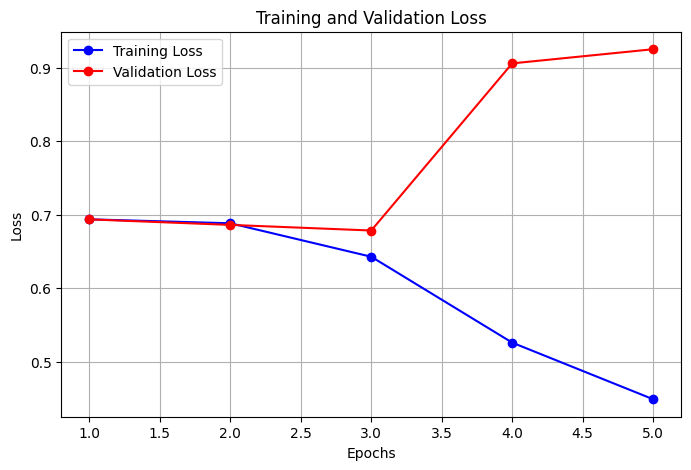

In [14]:
import matplotlib.pyplot as plt

# Extract loss values from history
train_loss = history.history['loss']
val_loss = history.history['val_loss']
epochs = range(1, len(train_loss) + 1)

# Create the plot
plt.figure(figsize=(8, 5))
plt.plot(epochs, train_loss, 'bo-', label='Training Loss')
plt.plot(epochs, val_loss, 'ro-', label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

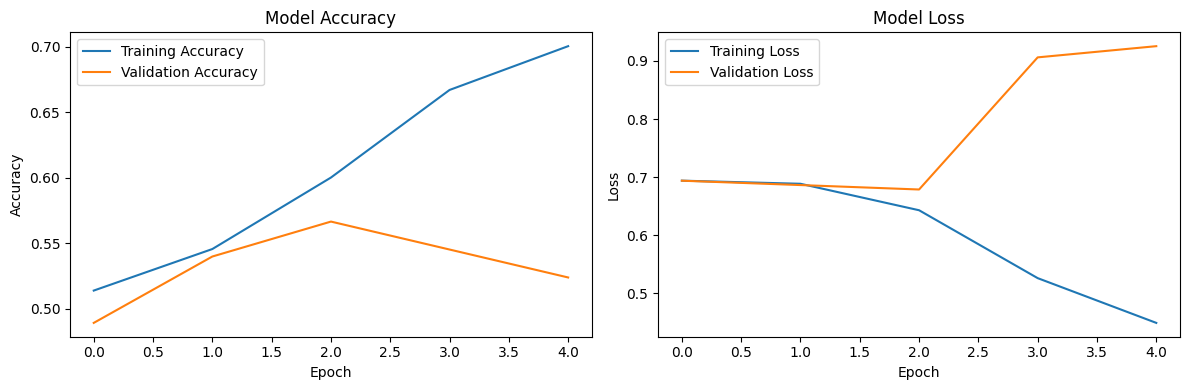

In [15]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [16]:
# Predict probabilities on test data
y_prob = model.predict(X_test_pad, verbose=0).ravel()

# Convert probabilities to class labels
y_pred = (y_prob >= 0.5).astype(int)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("MODEL EVALUATION RESULTS")
print("------------------------")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

print("\nDetailed Classification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Negative", "Positive"],
    zero_division=0
))

MODEL EVALUATION RESULTS
------------------------
Accuracy  : 0.5480
Precision : 0.5286
Recall    : 0.8880
F1-Score  : 0.6627

Detailed Classification Report:
              precision    recall  f1-score   support

    Negative       0.65      0.21      0.32       375
    Positive       0.53      0.89      0.66       375

    accuracy                           0.55       750
   macro avg       0.59      0.55      0.49       750
weighted avg       0.59      0.55      0.49       750



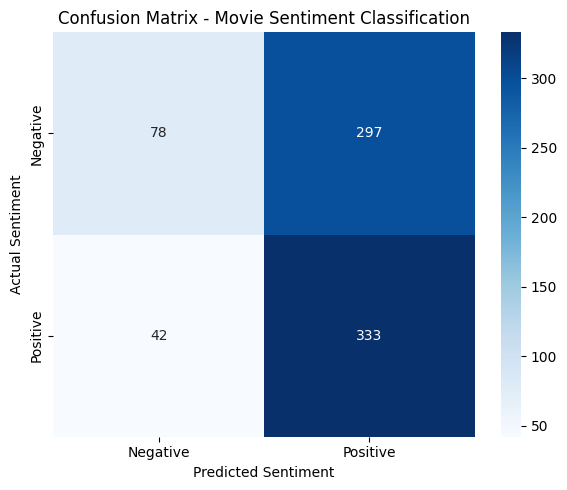

Confusion Matrix:
[[ 78 297]
 [ 42 333]]


In [17]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.title("Confusion Matrix - Movie Sentiment Classification")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.tight_layout()
plt.show()

print("Confusion Matrix:")
print(cm)

In [18]:
unseen_reviews = [
    "This movie was absolutely fantastic and the acting was brilliant.",
    "The film was boring and a complete waste of time.",
    "I loved the story, the music, and the wonderful performances.",
    "Terrible movie with a weak plot and disappointing acting.",
    "The movie was enjoyable and I would recommend it to everyone."
]

# Clean the unseen reviews
cleaned_reviews = [clean_text(review) for review in unseen_reviews]

# Tokenize and pad
new_sequences = tokenizer.texts_to_sequences(cleaned_reviews)

new_padded = pad_sequences(
    new_sequences,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

# Predict sentiment probabilities
probabilities = model.predict(new_padded, verbose=0).ravel()

# Display results
for i, (review, prob) in enumerate(
    zip(unseen_reviews, probabilities), start=1
):
    sentiment = "Positive" if prob >= 0.5 else "Negative"

    print(f"\nReview {i}: {review}")
    print(f"Predicted Sentiment: {sentiment}")
    print(f"Positive Probability: {prob:.4f}")


Review 1: This movie was absolutely fantastic and the acting was brilliant.
Predicted Sentiment: Positive
Positive Probability: 0.5003

Review 2: The film was boring and a complete waste of time.
Predicted Sentiment: Positive
Positive Probability: 0.5003

Review 3: I loved the story, the music, and the wonderful performances.
Predicted Sentiment: Positive
Positive Probability: 0.5003

Review 4: Terrible movie with a weak plot and disappointing acting.
Predicted Sentiment: Positive
Positive Probability: 0.5003

Review 5: The movie was enjoyable and I would recommend it to everyone.
Predicted Sentiment: Positive
Positive Probability: 0.5003
